# Experimentos para o processo de retrieval

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve().parent  # if notebook is in notebooks/
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd
from src.paths import PROC_DIR
from src.retrieval import BM25Retriever
from src.evaluation import map_relevance, evaluate_retrieval

In [3]:
products = pd.read_parquet(PROC_DIR / "products.parquet")
queries = pd.read_parquet(PROC_DIR / "queries.parquet")
labels = pd.read_parquet(PROC_DIR / "labels.parquet")
splits = pd.read_parquet(PROC_DIR / "splits.parquet")

In [4]:
labels["relevance"] = map_relevance(labels["label"])

In [5]:
ks = [10, 20, 50, 100, 200, 500]

## BM25

In [6]:
val_qids = set(splits.loc[splits["split"] == "val", "query_id"])
val_queries = queries[queries["query_id"].isin(val_qids)]
val_labels = labels[labels["query_id"].isin(val_qids)]

In [7]:
retriever = BM25Retriever().fit(products)
val_candidates = retriever.retrieve(val_queries, top_k=500)

In [8]:
candidates_500 = retriever.retrieve(val_queries, top_k=500)

In [9]:
curve_rows = []
for k in ks:
    sub = candidates_500[candidates_500["rank"] <= k]
    metrics = evaluate_retrieval(sub, val_labels, ks=[k])
    curve_rows.append({"k": k, "recall": metrics[f"recall@{k}"]})

In [10]:
curve_df = pd.DataFrame(curve_rows)

In [11]:
curve_df

,k,recall
0,10,0.064594
1,20,0.124251
2,50,0.250880
3,100,0.382986
4,200,0.536780
5,500,0.713295


<Axes: xlabel='k'>

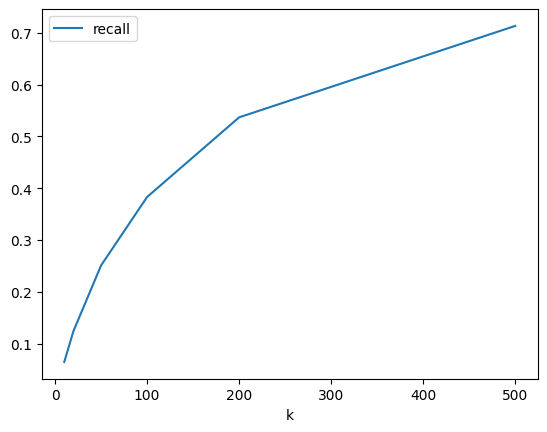

In [12]:
curve_df.plot(x='k', y='recall')